In [26]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
import matplotlib.pyplot as plt
import sklearn.datasets as datasets
import pandas as pd
import numpy as np
from scipy.stats import norm
from scipy import stats
from scipy import interpolate
import scipy.io as sio
from scipy.stats import kstest, anderson, jarque_bera
from scipy.stats import norm, chi2,beta
import math

import seaborn as sns
sns.set_style("whitegrid")

import torch
from torch import nn
from torch import optim
from torch.nn import functional as F

In [28]:
from ldf import ldf
from pit import pit
from pit import plot_pit_histograms

from pit import test_and_interpret_pit,ex_tlp_pdf
from utils.utils import geom_3f2,ex_tlp
from beta_transform import online_beta_calibration, plot_parameter_evolution
from Log_likelihood import log_score_comparison

### Exchange Rate Data

In [29]:
time = 342
exchange_rate = pd.read_excel(r'data/Y.xlsx',header=0, engine='openpyxl')[-time:]
exchange_rate .rename(columns={"Unnamed: 0": "Date"}, inplace=True)
exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])
exchange_rate

,Date,AUD,CAD,EUR,JPY,NZD,NOK,SEK,CHF,GBP
26,1992-02-29,0.002398,-0.006344,-0.019243,-0.028533,0.010823,-0.014269,-0.015061,-0.035017,-0.015798
27,1992-03-31,0.022593,-0.005887,-0.006373,-0.024849,-0.001464,-0.005968,-0.003772,-0.009207,-0.011840
28,1992-04-30,-0.017155,-0.001763,-0.004832,-0.003003,-0.014297,-0.003322,0.003617,-0.007417,0.024770
29,1992-05-31,0.000661,-0.009808,0.031786,0.043070,-0.003719,0.032956,0.026334,0.037444,0.027263
30,1992-06-30,-0.011232,0.003587,0.053167,0.016922,0.016986,0.049933,0.051953,0.060087,0.041477
...,...,...,...,...,...,...,...,...,...,...
363,2020-03-31,-0.057450,-0.047150,0.000408,0.005021,-0.047493,-0.096690,-0.031626,0.004684,-0.031357
364,2020-04-30,0.061115,0.008390,-0.006708,0.003359,0.028456,0.015512,0.015572,-0.004559,0.014012
365,2020-05-31,0.023959,0.012599,0.012960,-0.005567,0.012569,0.053658,0.035437,0.004161,-0.019695
366,2020-06-30,0.035398,0.014364,0.012073,-0.001390,0.040464,0.010157,0.011099,0.014888,0.004456


### LDF hyperparameters

In [30]:
y= np.array(exchange_rate['GBP'])[-time:]

In [31]:
currency_idx = 8
mat = sio.loadmat(r'data/y_t_pred.mat')
y_t_pred = mat['y_t_pred']
forecast = y_t_pred[-time:,currency_idx,:].T

In [32]:
loglik_ind = sio.loadmat(r'data//log lik ind.mat')
loglik_ind = loglik_ind['log_predlik_ind'][-time:,currency_idx,:].T

In [33]:
sigma = sio.loadmat(r'data/sigma.mat')
sigma = sigma['SIGMA_t'][currency_idx,currency_idx,-time:,:].T

In [34]:
discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
c = 10**-20 

### 2-level LDF(softmax, softmax)

In [35]:
%%time
res_ldf = ldf(loglik_ind, levels=2, discount_factors=[discount_factors, discount_factors], activation_functions=["softmax", "softmax"], c=c)
res_ldf_df = pd.DataFrame({'discount factors': discount_factors, 'log likelihood': res_ldf["logscores"].mean(axis=1)}) #
res_ldf_df

CPU times: total: 266 ms
Wall time: 273 ms


,discount factors,log likelihood
0,1.000,2.163992
1,0.990,2.167332
2,0.950,2.165934
3,0.900,2.161703
4,0.800,2.158581
5,0.700,2.157498
6,0.600,2.156917
7,0.500,2.156525
8,0.400,2.156231
9,0.300,2.155989


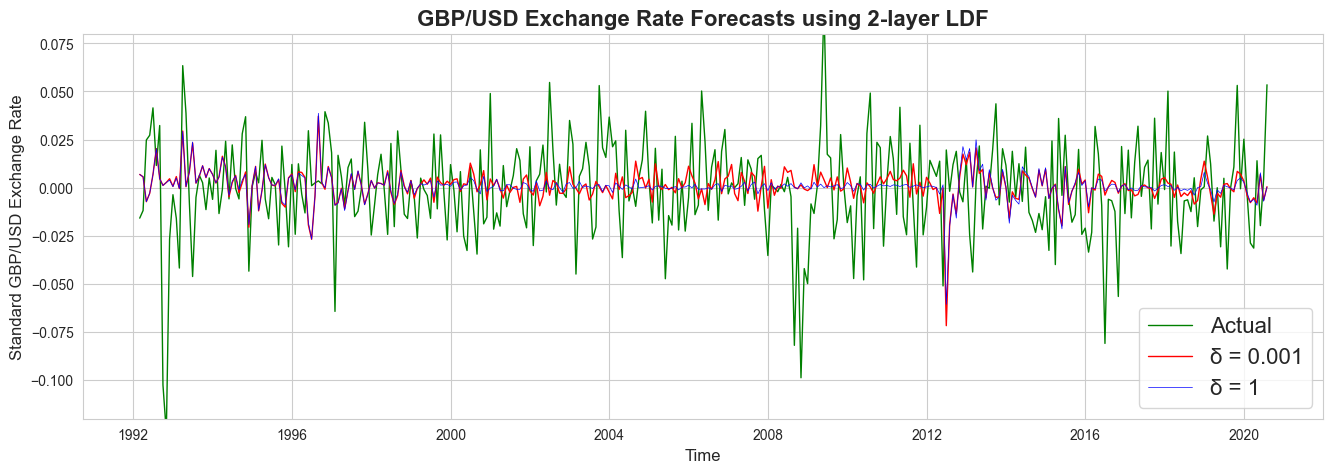

In [36]:
sns.color_palette("tab10")
discount_0001 = (res_ldf["weights"][-1][-time:]*forecast.T).sum(axis=1)
discount_1 = (res_ldf["weights"][0][-time:]*forecast.T).sum(axis=1)
date = exchange_rate['Date']
fig, ax = plt.subplots(1, 1, figsize=(16,5))
ax.plot(date,y,'g-', lw=1, label='Actual')
ax.plot(date,discount_0001,'r-', lw=1, label='δ = 0.001')
ax.plot(date,discount_1,'b-', lw=0.5, label='δ = 1')
ax.set_ylabel('Standard GBP/USD Exchange Rate',fontsize=12)
ax.set_xlabel('Time',fontsize=12)
ax.set_ylim(-0.12,0.08)
ax.set_title('GBP/USD Exchange Rate Forecasts using 2-layer LDF', fontsize=16, fontweight='bold')
ax.legend(loc='lower right', fontsize=16)

### x grid

In [37]:
weights = res_ldf["weights"][:,-time:,:] #  # Transpose to (P, T, K)

# Grid setup
f = forecast.flatten()
mu_min, mu_max = f.min(), f.max()
margin = 5 * np.sqrt(sigma.max())  # Use sqrt for standard deviation
x_min = mu_min - margin
x_max = mu_max + margin
M = 181
x_grid = np.linspace(x_min, x_max, M)


# Calculate linear pool
linear_pool = ex_tlp(forecast, sigma, x_grid, weights)

### Beta Transform

In [38]:
ex_tlp_param = {
    'forecast': forecast,
    'var': sigma,
    'x': x_grid,
    'weights': weights
}

ex_beta_transform = online_beta_calibration(
    x=x_grid,
    y_observations=y,
    pool_func=ex_tlp,
    pool_param=ex_tlp_param,
    geom_3f2=geom_3f2,
    # Core BFGS/Newton parameters
    a0=1.0,
    b0=1.0,
    gamma=0.1,
    eta0=1,
    tau=50,
    alpha=0.55,
    # Basic calibration parameters
    outer_loop_freq=40,              # Correction frequency (t_freq in algorithm)
    min_samples=40,                  # Minimum samples for corrections (n_min in algorithm)
    
    # Algorithm 2: Shape detection parameters
    significance_level=0.05,          # α - significance level for chi-square tests
    k_bins_for_detection=10,          # k - number of bins for shape detection
    
    # Algorithm 3: Shape-specific correction parameters
    correction_strength=0.4,        # λ - blend parameter for corrections
    param_floor=0.25,               # Lower bound for α,β parameters
    param_ceiling=5.00,             # Upper bound for α,β parameters
    
    # Window management
    rolling_window_size=75,        # w - rolling window size for corrections         
    x_constant=1.2,
    # Numerical stability
    eps=1e-5
)

Starting Online Beta Calibration
  Models (P): 12
  Time steps (T): 342
  Grid points (M): 181
  Initial parameters: α₀=1.0, β₀=1.0
  Learning rate: η₀=1, τ=50, α=0.55
  Correction strength: 0.4
------------------------------------------------------------
Step    0: α=0.9986, β=1.0010
Step  200: α=2.1316, β=2.1886
------------------------------------------------------------
Online Beta Calibration Complete


### Beta Parmaeter Evolution

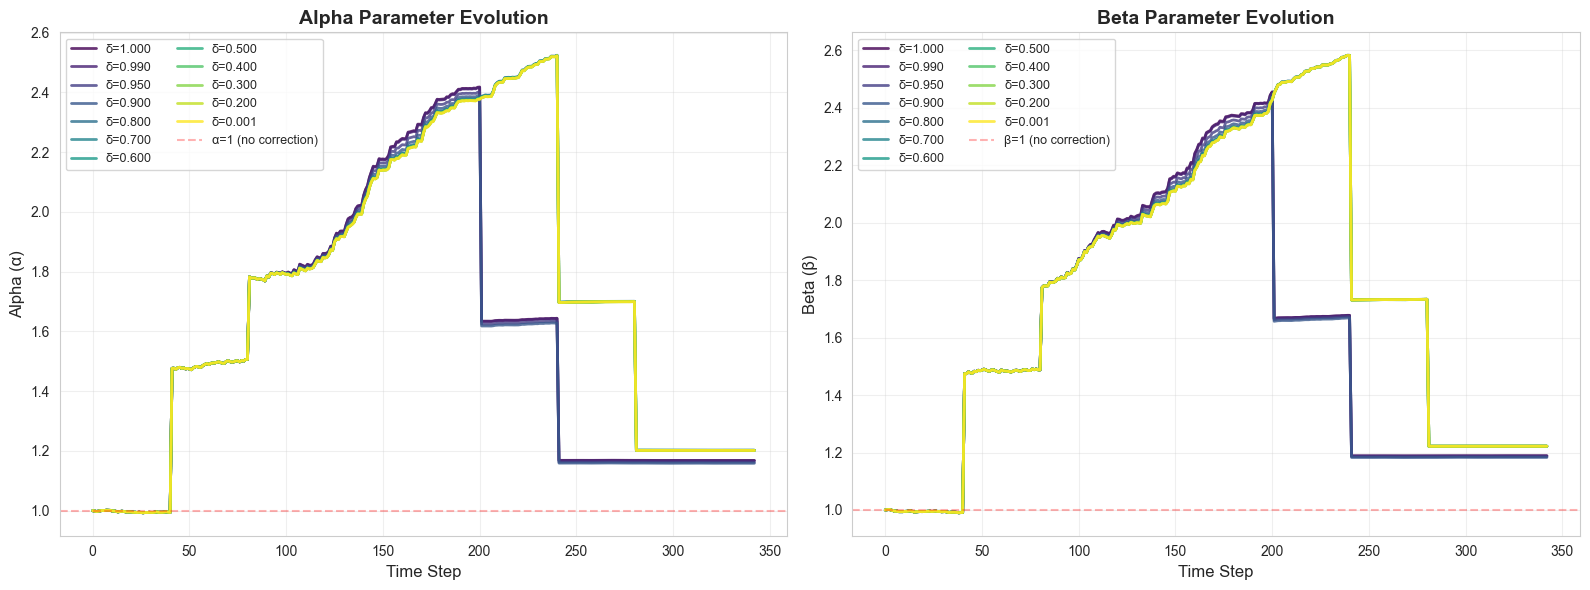

In [39]:
plot_parameter_evolution(ex_beta_transform, discount_factors)

### Uniformity Results Comparison

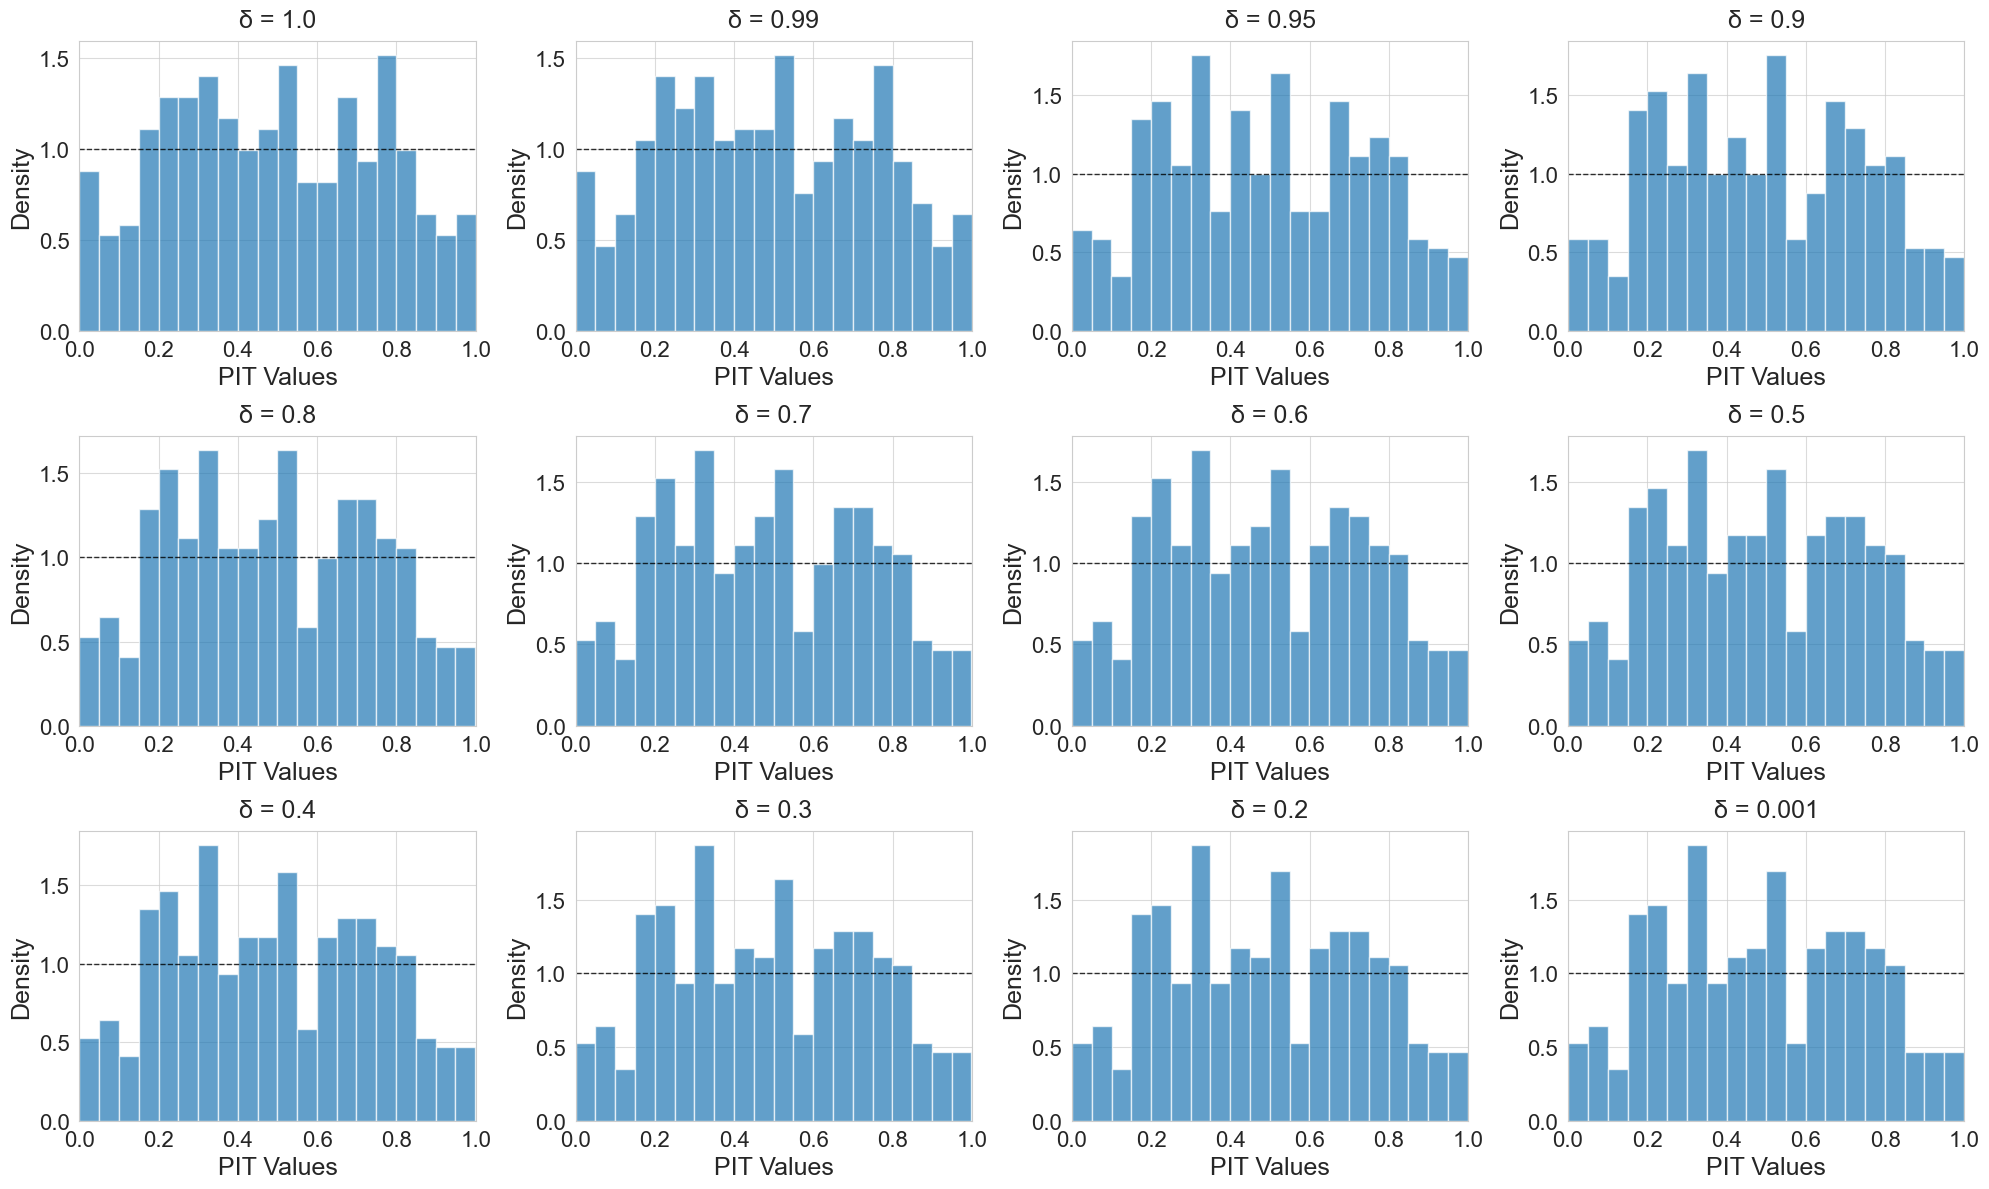

In [40]:
TLP = pit(linear_pool, x_grid,y)

plot_pit_histograms(TLP, model_names=discount_factors)

In [41]:
_, beta_orig_df = test_and_interpret_pit(
    pit_values=TLP,
    discount_factors=discount_factors
)
beta_orig_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,4/9,PASS,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,PASS,PASS
1,δ = 0.99,4/9,PASS,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,PASS,PASS
2,δ = 0.95,2/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,PASS,FAIL
3,δ = 0.9,2/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,PASS,FAIL
4,δ = 0.8,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
5,δ = 0.7,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
6,δ = 0.6,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
7,δ = 0.5,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
8,δ = 0.4,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
9,δ = 0.3,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL


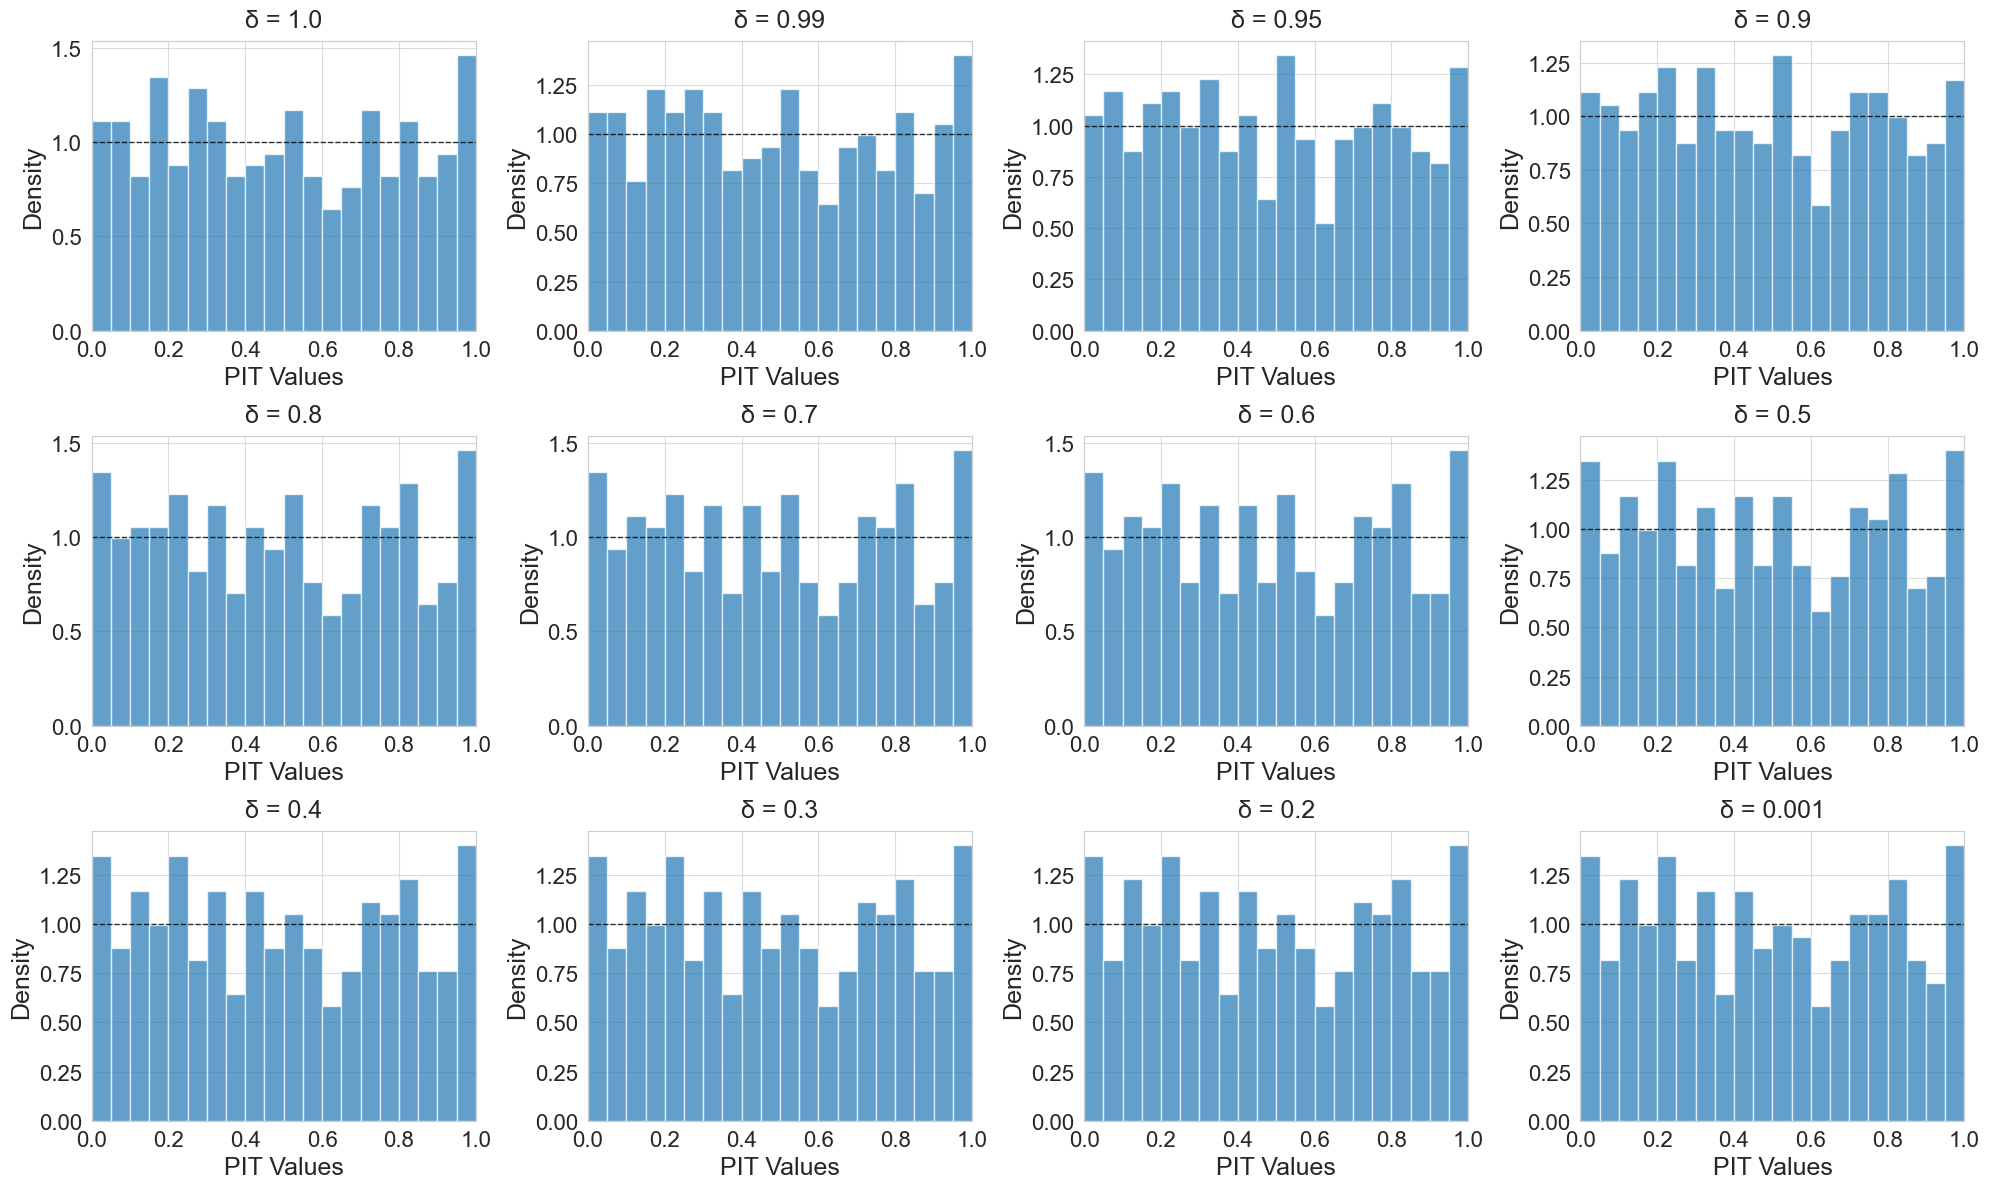

In [42]:
plot_pit_histograms(ex_beta_transform['all_calibrated_cdfs'], model_names=discount_factors)

In [43]:
_, beta_tran_df = test_and_interpret_pit(
    pit_values=ex_beta_transform['all_calibrated_cdfs'],
    discount_factors=discount_factors
)
beta_tran_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,5/9,PASS,PASS,FAIL,FAIL,PASS,PASS,FAIL,PASS,FAIL
1,δ = 0.99,6/9,PASS,PASS,FAIL,FAIL,PASS,PASS,FAIL,PASS,PASS
2,δ = 0.95,7/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,PASS
3,δ = 0.9,7/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,PASS
4,δ = 0.8,6/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,FAIL
5,δ = 0.7,6/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,FAIL
6,δ = 0.6,6/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,FAIL
7,δ = 0.5,7/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,PASS
8,δ = 0.4,7/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,PASS
9,δ = 0.3,7/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,PASS


### Log Likelihood Comparison

In [44]:
ex_pdf = ex_tlp_pdf(forecast,sigma,x_grid,weights,y)

ex_log_pdf = np.log(ex_pdf)

beta_ll = log_score_comparison(ex_beta_transform['all_calibrated_cdfs'], 
                           np.array(ex_beta_transform['a_hist'][:,1:]), 
                           np.array(ex_beta_transform['b_hist'][:,1:]), 
                           TLP, 
                           ex_pdf,
                           ex_log_pdf,
                           discount_factors)

beta_ll

,discount_factor,Before Calibration,After Calibration,Comparison
0,1.000,2.175544,2.097012,Lower Log Score
1,0.990,2.175119,2.106003,Lower Log Score
2,0.950,2.183630,2.155301,Lower Log Score
3,0.900,2.179857,2.164577,Lower Log Score
4,0.800,2.176765,2.111078,Lower Log Score
5,0.700,2.175434,2.112123,Lower Log Score
6,0.600,2.174660,2.112403,Lower Log Score
7,0.500,2.174157,2.112481,Lower Log Score
8,0.400,2.173802,2.112492,Lower Log Score
9,0.300,2.173536,2.112473,Lower Log Score


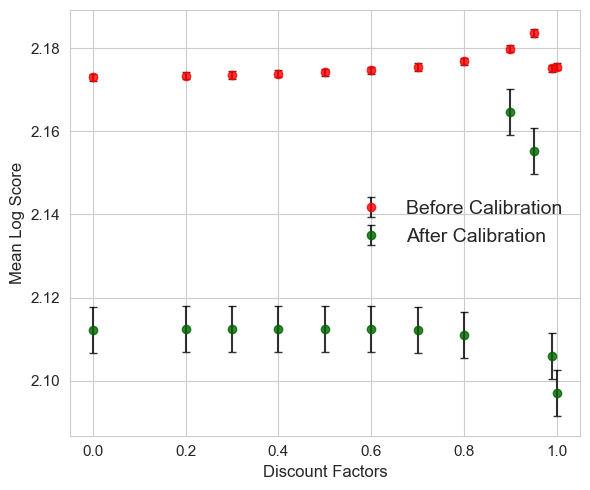

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(6,5))

beta_before_mean_log_score = beta_ll['Before Calibration']
beta_after_mean_log_score = beta_ll['After Calibration']

# Example: assuming you have std errors (replace with your arrays)
ex_before_std = np.std(beta_before_mean_log_score) / np.sqrt(len(beta_before_mean_log_score))
ex_after_std = np.std(beta_after_mean_log_score) / np.sqrt(len(beta_after_mean_log_score))
ax.errorbar(discount_factors, beta_before_mean_log_score, 
            yerr=ex_before_std, fmt='o', 
            mfc='red', mec='red', ecolor='black', 
            label="Before Calibration", markersize=6, capsize=3, alpha=0.8)

ax.errorbar(discount_factors, beta_after_mean_log_score, 
            yerr=ex_after_std, fmt='o', 
            mfc='darkgreen', mec='darkgreen', ecolor='black', 
            label="After Calibration", markersize=6, capsize=3, alpha=0.8)
ax.set_ylabel("Mean Log Score", fontsize=12)
ax.set_xlabel("Discount Factors", fontsize=12)

ax.legend(loc="center right", frameon=False, fontsize=14)
ax.tick_params(axis='both', labelsize=11)

fig.tight_layout()